# 07 · Pure premium: frequency × severity, county credibility, Tweedie, loss ratios (Milestone 9)

**Goal:** turn the two models into an **expected loss cost per policy-year** (the **pure premium**) for every rating cell, and check it from several angles.

> pure premium = base rate × base severity × (each factor's relativity) × large-loss load × ICC bridge × off-balance × county factor

What this notebook does:
1. **Combine** the saved frequency GLM (notebook 05) and severity GLM (notebook 06), apply the large-loss load and an **off-balance correction**, and build one relativity table with frequency, severity and pure-premium relativities.
2. **Credibility-weighted county factor** (Theo's Question 7): each county's actual ÷ expected against the GLM, blended with 1 by **credibility**, for frequency and severity. Two standard methods (limited fluctuation, Bühlmann–Straub), validated on held-out years.
3. **Tweedie GLM** for pure premium in one step, compared with frequency × severity: A/E, lift, **double lift**, Gini.
4. **Loss ratios** from the actual NFIP premiums, and modelled loss cost vs premium by segment.
5. **Rating worksheets** for five example Virginia profiles.

**Code:** `src/models/pure_premium.py` (this notebook only calls it), `src/models/frequency_glm.py`, `src/models/severity_glm.py`, `src/validation.py`. **Write-up:** `reports/06_pure_premium.md`.

> Area-level analysis of aggregated public data. Every number describes the average for a *group* of similar insured buildings, never an individual property.

In [1]:
import hashlib
import json
import sys
import warnings
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import build_dataset as bd
import validation as val
from models import frequency_glm as fg
from models import severity_glm as sv
from models import pure_premium as pp

warnings.filterwarnings("ignore")
FIG = ROOT / "reports" / "figures"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"     # freq x sev / Tweedie or comparison / third
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "font.size": 9.5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "legend.frameon": False, "text.usetex": False, "text.parse_math": False,
})

def save(fig, name):
    path = FIG / f"07_{name}.png"
    fig.savefig(path)
    print(f"saved {path.relative_to(ROOT)}")

def log_rel_axis(ax, lo=0.25, hi=4, axis="x"):
    ticks = [t for t in [0.1, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 8] if lo <= t <= hi]
    a = ax.xaxis if axis == "x" else ax.yaxis
    (ax.set_xscale if axis == "x" else ax.set_yscale)("log")
    (ax.set_xlim if axis == "x" else ax.set_ylim)(lo, hi)
    a.set_major_locator(mticker.FixedLocator(ticks))
    a.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
    a.set_minor_locator(mticker.NullLocator())
    (ax.axvline if axis == "x" else ax.axhline)(1, color=MUTED, lw=1, ls="--", zorder=1)

LABELS = {"flood_zone_group": "Flood zone", "occupancy_group": "Occupancy", "floors_group": "Floors",
          "elevated": "Elevated", "primary_residence": "Primary residence", "post_firm": "Post-FIRM",
          "construction_band": "Year built", "building_coverage_band": "Building coverage"}

## 1. Combining frequency and severity
For each rating cell (county × year × building features):

> expected losses = exposure × [frequency per policy-year] × [severity per claim] × ICC bridge × off-balance

- **Frequency** and **severity** come from the saved models, each at its **average-year** level (a future year's weather is unknown).
- **Large-loss load:** Milestone 8 decided **not** to cap claims (NFIP limits already cap the tail, and capping didn't help on unseen years), so the load is **1.0**. The machinery stays: section 1c shows what a 99th-percentile cap with its 1.034 load would change.
- **ICC bridge** (1.0092): the severity model covers building + contents only; this adds Increased Cost of Compliance payments back.
- **Off-balance:** the final multiplier that makes predicted total losses equal actual total losses (calculated below).

In [2]:
cells = pd.read_parquet(pp.CELLS_PATH)
claims = sv.load_claims()
freq, sev, sev_json = pp.load_saved_models()
FF, SF = list(freq.spec.features), list(sev.spec.features)
FB, SB = pp.bases_without_year(freq.spec), pp.bases_without_year(sev.spec)
print("frequency features:", FF)
print("severity features: ", SF)

# Refitting from the data reproduces the saved models exactly (and gives us the off-balance).
model = pp.fit_combined(cells, claims, FF, SF, FB, SB)
assert np.allclose(model.freq.params, freq.params) and np.allclose(model.sev.params, sev.params)
assert np.isclose(model.icc_bridge, sev_json["icc_bridge_factor"])
print(f"large-loss load {model.large_loss_load:.3f}, ICC bridge {model.icc_bridge:.4f}, off-balance {model.off_balance:.4f}")
pred = model.predict(cells, county=False)
assert np.isclose(pred.sum(), cells[pp.LOSS].sum())
print(f"predicted total ${pred.sum():,.0f} = actual total ${cells[pp.LOSS].sum():,.0f}")

frequency features: ['flood_zone_group', 'construction_band', 'floors_group']
severity features:  ['occupancy_group', 'construction_band', 'building_coverage_band', 'flood_zone_group', 'floors_group', 'primary_residence', 'elevated']


large-loss load 1.000, ICC bridge 1.0092, off-balance 0.9933


predicted total $292,685,981 = actual total $292,685,981


### 1a. The off-balance correction, step by step
Each model is calibrated on its own: frequency predictions add up to actual claims, and severity predictions to actual claim dollars. Their **product** needn't add up to actual losses, for three reasons:
1. **Mix:** frequency × severity is computed cell by cell. If cells with higher-than-average frequency also have lower-than-average severity (or vice versa), the total of the products differs from total claims × average claim. That's *the average of a product isn't the product of the averages*. The Gamma log link also balances ratios rather than dollars (Milestone 8).
2. **ICC:** added back as an average bridge factor, not cell by cell.
3. **Unmatched claims:** 1.23% of losses sit in cells with no exposure, so frequency can't predict them.

> off-balance = actual total losses ÷ predicted total losses (before the correction)

In [3]:
m_cells = cells[cells["exposure"] > 0]
comp = model.components(m_cells, county=False)
p_bc = (m_cells["exposure"].to_numpy() * comp["frequency"] * comp["severity"]).sum()   # building + contents, no ICC
sev_rows = sv.severity_rows(claims)
a_bc_matched = sev_rows.loc[sev_rows["exposure_matched"], sv.TARGET].sum()
a_matched = m_cells[pp.LOSS].sum()
a_total = cells[pp.LOSS].sum()
steps = pd.Series({
    "1. mix: actual b+c in matched cells / predicted b+c": a_bc_matched / p_bc,
    "2. ICC: actual ICC share in matched cells / ICC bridge": (a_matched / a_bc_matched) / model.icc_bridge,
    "3. unmatched claims: all losses / matched-cell losses": a_total / a_matched})
steps["off-balance (product)"] = steps.prod()
print(steps.round(4).to_string())
assert np.isclose(steps["off-balance (product)"], model.off_balance)

1. mix: actual b+c in matched cells / predicted b+c       0.9808
2. ICC: actual ICC share in matched cells / ICC bridge    1.0005
3. unmatched claims: all losses / matched-cell losses     1.0122
off-balance (product)                                     0.9933


Base building (A/V, single-unit, built 1980-99, 2 floors, $250K+, primary, not elevated), average year:
  frequency 4.82 per 1,000 policy-years x severity $28,498 x ICC 1.0092 x off-balance 0.9933 = $137.83 per policy-year
            label                   level  is_base  frequency_rel  severity_rel  pure_premium_rel
       Flood zone           A/V high risk     True          1.000         1.000             1.000
       Flood zone B/C/X moderate-low risk    False          0.458         0.746             0.341
       Year built               1980-1999     True          1.000         1.000             1.000
       Year built             before 1960    False          2.728         1.022             2.788
       Year built               1960-1979    False          2.748         1.282             3.523
       Year built           2000 or later    False          0.643         0.897             0.576
           Floors                       2     True          1.000         1.000            

saved reports\figures\07_combined_relativities.png


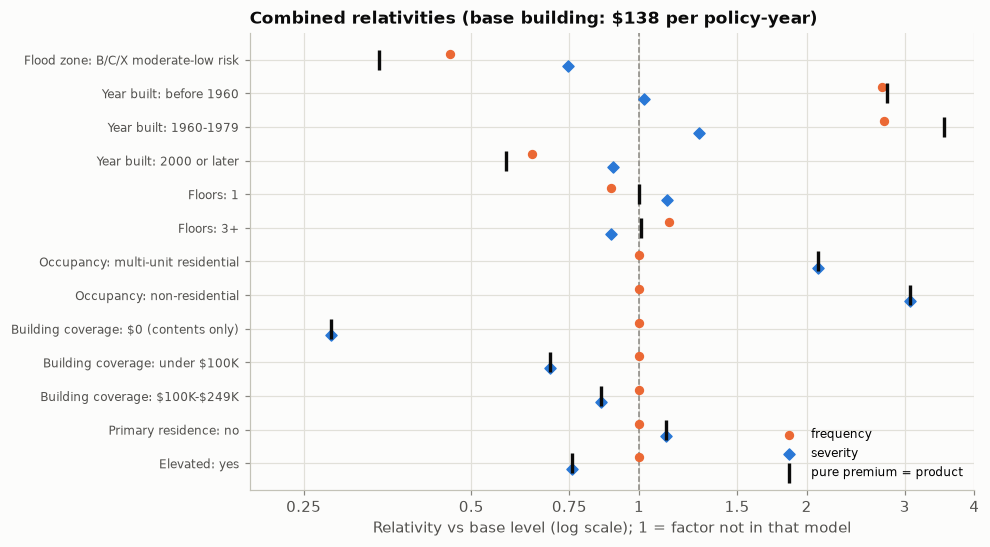

In [4]:
rel = pp.combined_relativity_table(freq, sev)
rel["label"] = rel["feature"].map(LABELS)
BASE_PP = model.base_pure_premium()
base_f = float(np.exp(freq.params["const"] + freq.avg_year_log))
base_s = float(np.exp(sev.params["const"] + sev.avg_year_log))
print(f"Base building (A/V, single-unit, built 1980-99, 2 floors, $250K+, primary, not elevated), average year:")
print(f"  frequency {1000 * base_f:.2f} per 1,000 policy-years x severity ${base_s:,.0f} x ICC {model.icc_bridge:.4f} "
      f"x off-balance {model.off_balance:.4f} = ${BASE_PP:,.2f} per policy-year")
print(rel[["label", "level", "is_base", "frequency_rel", "severity_rel", "pure_premium_rel"]].round(3).to_string(index=False))

nb_ = rel[~rel["is_base"]].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 5.4))
yy = np.arange(len(nb_))[::-1]
ax.scatter(nb_["frequency_rel"], yy + 0.18, color=ORANGE, s=26, label="frequency", zorder=3)
ax.scatter(nb_["severity_rel"], yy - 0.18, color=BLUE, s=26, marker="D", label="severity", zorder=3)
ax.barh(yy, np.log(nb_["pure_premium_rel"]), left=0, height=0.0)   # keeps the y-limits stable
ax.scatter(nb_["pure_premium_rel"], yy, color=INK, marker="|", s=170, lw=2.2, label="pure premium = product", zorder=4)
ax.set_yticks(yy, nb_["label"] + ": " + nb_["level"].replace({"True": "yes", "False": "no"}), fontsize=8)
log_rel_axis(ax, 0.2, 4)
ax.set(xlabel="Relativity vs base level (log scale); 1 = factor not in that model",
       title=f"Combined relativities (base building: ${BASE_PP:,.0f} per policy-year)")
ax.legend(loc="lower right", fontsize=8)
save(fig, "combined_relativities")

### 1c. Sensitivity: what a large-loss cap would change
Refit the severity model on claims capped at the 99th percentile, with the large-loss load putting the capped dollars back (Milestone 8's documented alternative).

In [5]:
sev99 = sv.fit_gamma(sv.severity_rows(claims), SF, cap_quantile=0.99, bases=SB)
m99 = pp.CombinedModel(freq, sev99, model.icc_bridge)
m99.off_balance = pp.off_balance_factor(m99, cells)
r99 = pp.combined_relativity_table(freq, sev99).set_index(["feature", "level"])["pure_premium_rel"]
r00 = rel.set_index(["feature", "level"])["pure_premium_rel"]
print(f"P99 cap ${sev99.cap:,.0f}, load {sev99.load:.3f}, off-balance {m99.off_balance:.4f}, base pure premium ${m99.base_pure_premium():,.2f} (vs ${BASE_PP:,.2f})")
chg = (r99 / r00 - 1) * 100
print("Largest relativity changes (%):")
print(chg.abs().sort_values(ascending=False).head(4).round(1).to_string())

P99 cap $241,051, load 1.034, off-balance 0.9959, base pure premium $139.55 (vs $137.83)
Largest relativity changes (%):
feature                 level                 
occupancy_group         non-residential           13.5
building_coverage_band  $0 (contents only)         4.6
occupancy_group         multi-unit residential     2.9
building_coverage_band  under $100K                2.1


## 2. A credibility-weighted county factor (Question 7)
The GLMs have **no geography**: county effects failed on unseen years in both milestones, because *which* counties flood depends on where each storm goes. But the app needs county differences, and the leftover county A/E is large (Newport News, Norfolk). **Credibility** is the actuarial answer to "how much should I trust this county's own experience?":

> county factor = Z × (county's A/E) + (1 − Z) × 1

- **A/E** = actual ÷ GLM-expected for that county.
- **Z** (between 0 and 1) = credibility. Z = 1: trust the county fully. Z = 0: use the statewide model (factor 1).

It's done separately for frequency and severity, and the county factor = frequency factor × severity factor.
- **Frequency A/E** uses each year's *fitted* year effect, so a storm year's overall level isn't counted as a county effect.
- **Severity A/E** is actual vs expected building + contents dollars per claim.

In [6]:
names = cells.drop_duplicates("county").set_index("county")["county_name"]
by, cy = pp.county_ae(model, cells, claims)
by["name"] = by.index.map(names)
SEV_CV = float(sev_rows[sv.TARGET].std() / sev_rows[sv.TARGET].mean())
print(f"{len(by)} counties (incl. 'UNKNOWN'); severity coefficient of variation CV = {SEV_CV:.3f}")
print(by.sort_values("f_act", ascending=False).head(15)[["name", "f_act", "f_exp", "freq_ae", "s_n", "sev_ae"]].round(3).to_string())

142 counties (incl. 'UNKNOWN'); severity coefficient of variation CV = 1.583
                         name  f_act     f_exp  freq_ae     s_n  sev_ae
county                                                                 
51810     Virginia Beach city   2070  1604.816    1.290  2072.0   1.147
51710            Norfolk city   1332  1170.390    1.138  1333.0   0.795
51650            Hampton city    834  1309.905    0.637   834.0   0.760
51550         Chesapeake city    619   642.316    0.964   622.0   0.778
51059          Fairfax County    517   394.919    1.309   518.0   0.964
51740         Portsmouth city    423   417.520    1.013   425.0   0.819
51735           Poquoson city    410   389.192    1.053   409.0   0.782
51700       Newport News city    337   223.212    1.510   339.0   1.757
51001         Accomack County    327   408.620    0.800   327.0   1.108
51510         Alexandria city    168   112.039    1.499   171.0   1.166
51153   Prince William County    135    84.477    1.598   1

### 2a. Method 1: limited fluctuation ("classical") credibility
**Idea:** trust a county fully once it has enough claims that its A/E is unlikely to be off by more than **k = 5%**, with probability **p = 90%**. Below that, use the **square-root rule**:
- **Full-credibility standard for frequency:** n_full = (z ÷ k)², where z = 1.645 is the normal-distribution value that leaves 90% in the middle. So n_full = (1.645 ÷ 0.05)² ≈ **1,082 claims**, the same standard used for credibility flags since Milestone 6.
- **For severity:** n_full × CV², because claim sizes vary (CV = sd ÷ mean of a claim, about 1.58 here), so you need more claims to pin down an average size.
- **Partial credibility:** Z = min(1, √(n ÷ n_full)). *Example:* a county with 270 claims has Z = √(270 ÷ 1,082) = 0.50 for frequency.

*Weakness here:* it assumes claims are independent. Flood claims arrive in storms, so 2,000 claims from one hurricane carry much less information than 2,000 independent claims.

In [7]:
lf_tbl, lf_par = pp.credibility_factors(by, cy, "limited_fluctuation", sev_cv=SEV_CV)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in lf_par.items()})

{'method': 'limited_fluctuation', 'p': 0.9, 'k': 0.05, 'n_full_freq': 1082.217, 'sev_cv': 1.583, 'n_full_sev': 2712.605}


### 2b. Method 2: Bühlmann–Straub ("greatest accuracy") credibility
**Idea:** let the data say how noisy a county's experience is, using its **year-to-year** swings. A storm that floods one county shows up as a big swing, so storm clumping is built in.
- **EPV** ("expected process variance"): how much a county's A/E bounces around from year to year (per unit of weight). That's noise.
- **VHM** ("variance of hypothetical means"): how much the counties' *true* long-run A/Es differ. That's signal.
- **k = EPV ÷ VHM**, and **Z = w ÷ (w + k)**, where w is the county's weight (expected claims for frequency, claim count for severity). *Example:* if k = 33 claims, a county with 300 claims gets Z = 300 ÷ 333 = 0.90.
- If the estimated VHM is ≤ 0, the counties' differences are no bigger than the noise predicts: k = ∞ and Z = 0 for everyone.

In [8]:
bs_tbl, bs_par = pp.credibility_factors(by, cy, "buhlmann_straub")
for part in ["freq", "sev"]:
    q = bs_par[part]
    print(f"{part}: EPV {q['epv']:.3f}, VHM {q['vhm']:.4f}, k = {q['k']:.1f}" + ("  (VHM <= 0, so Z = 0)" if not np.isfinite(q["k"]) else ""))

freq: EPV 17.092, VHM -0.0486, k = inf  (VHM <= 0, so Z = 0)
sev: EPV 2.251, VHM 0.0674, k = 33.4


saved reports\figures\07_credibility_z.png


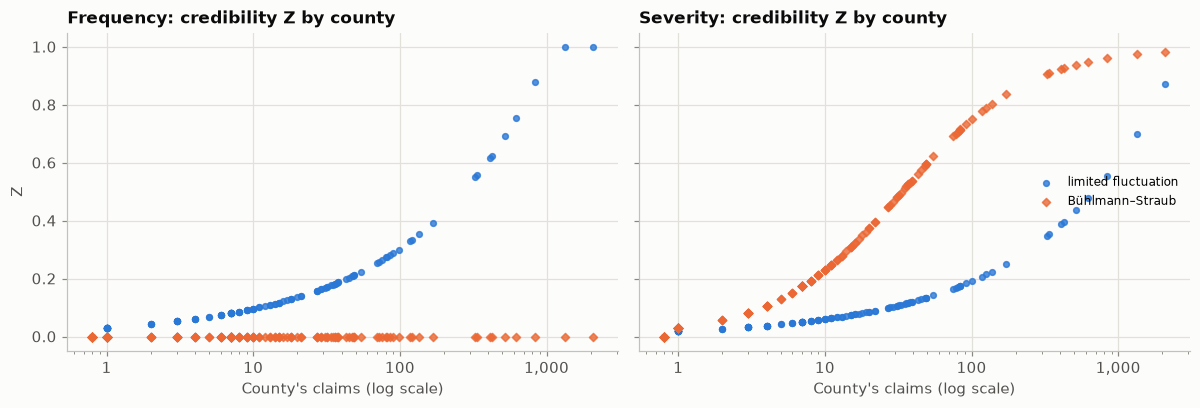

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, n_col, title in [(axs[0], "Z_freq", "f_act", "Frequency"), (axs[1], "Z_sev", "s_n", "Severity")]:
    for t_, name, c_, mk in [(lf_tbl, "limited fluctuation", BLUE, "o"), (bs_tbl, "Bühlmann–Straub", ORANGE, "D")]:
        ax.scatter(t_[n_col].clip(lower=0.8), t_[col], s=14, color=c_, marker=mk, label=name, alpha=0.8)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))
    ax.set(title=f"{title}: credibility Z by county", xlabel="County's claims (log scale)")
axs[0].set_ylabel("Z")
axs[1].legend(fontsize=8, loc="center right")
fig.tight_layout()
save(fig, "credibility_z")

### 2c. Validation: does a county factor help on years it hasn't seen?
For each held-out year, both GLMs are refitted on the other years, county factors are estimated **from the other years only**, and the held-out year is predicted. The comparison is the GLM alone vs + each county factor:
- **Held-out county A/E:** out-of-fold predictions re-based within each year, then pooled by county. The summary is the claim-weighted mean |log A/E| (0 = perfect) and the share of counties within 0.8–1.25, for counties with ≥ 30 claims.
- **Overall fit:** re-based Tweedie deviance improvement over a no-features model (scored at power 1.5, a common yardstick), and the Gini.

It's reported for all 16 LOYO years, the development years, and the 2021–2025 holdout.

In [10]:
TW_FEATURES = SF                     # the union of the frequency and severity features
TW_POWER_GRID = [1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8]
dev_c, dev_k = cells[cells["year"] <= val.LAST_TRAIN_YEAR], claims[claims["year"] <= val.LAST_TRAIN_YEAR]

# Tweedie power chosen on development years (section 3), needed for the joint LOYO run below.
grid = []
for p_ in TW_POWER_GRID:
    for yr, tr, te in val.leave_one_year_out(dev_c):
        tw = pp.fit_tweedie(tr, TW_FEATURES, p_)
        test = te[te["exposure"] > 0]
        grid.append({"power": p_, "test_year": yr, **pp.score_cells(test, tw.predict(test), tr[pp.LOSS].sum() / tr["exposure"].sum(),
                                                                  all_test_losses=te[pp.LOSS].sum())})
grid = pd.DataFrame(grid)
grid_summ = grid.groupby("power")[["improvement_rebased_pct", "gini"]].mean()
TW_POWER = float(grid_summ["improvement_rebased_pct"].idxmax())
print(grid_summ.round(3).to_string()); print("chosen Tweedie power:", TW_POWER)

METHODS = ("limited_fluctuation", "buhlmann_straub")
sc_all, oof = pp.loyo_combined(cells, claims, FF, SF, FB, SB, tweedie_features=TW_FEATURES, tweedie_power=TW_POWER,
                               county_methods=METHODS, sev_cv=SEV_CV, keep_cols=SF)
sc_dev, _ = pp.loyo_combined(dev_c, dev_k, FF, SF, FB, SB, tweedie_features=TW_FEATURES, tweedie_power=TW_POWER,
                             county_methods=METHODS, sev_cv=SEV_CV)
assert len(oof) == (cells["exposure"] > 0).sum()
MODEL_NAMES = list(sc_all["model"].unique())
FS, FS_LF, FS_BS, TW = MODEL_NAMES[0], MODEL_NAMES[1], MODEL_NAMES[2], MODEL_NAMES[3]
print(MODEL_NAMES)

       improvement_rebased_pct   gini
power                                
1.2                     10.895  0.468
1.3                     11.621  0.482
1.4                     12.199  0.488
1.5                     12.627  0.490
1.6                     12.900  0.497
1.7                     13.008  0.501
1.8                     12.941  0.503
chosen Tweedie power: 1.7


['freq x sev', 'freq x sev + county (limited_fluctuation)', 'freq x sev + county (buhlmann_straub)', 'Tweedie p=1.7']


In [11]:
tr_c, te_c = val.time_holdout(cells)
tr_k, _ = val.time_holdout(claims)
mh = pp.fit_combined(tr_c, tr_k, FF, SF, FB, SB)
test_h = te_c[te_c["exposure"] > 0]
rate_h = tr_c[pp.LOSS].sum() / tr_c["exposure"].sum()
hold_preds = {FS: mh.predict(test_h, county=False)}
for meth, name in zip(METHODS, [FS_LF, FS_BS]):
    mc_, _, _ = pp.with_county_factors(mh, tr_c, tr_k, meth, sev_cv=SEV_CV)
    hold_preds[name] = mc_.predict(test_h)
tw_h = pp.fit_tweedie(tr_c, TW_FEATURES, TW_POWER)
hold_preds[TW] = tw_h.predict(test_h)
hold = pd.DataFrame({k: pp.score_cells(test_h, v, rate_h, all_test_losses=te_c[pp.LOSS].sum()) for k, v in hold_preds.items()}).T

def summarize(sc):
    s = sc.assign(cat=sc["test_year"].isin(val.CAT_YEARS))
    return pd.DataFrame({"mean improvement %": s.groupby("model")["improvement_rebased_pct"].mean(),
                         "non-cat %": s[~s["cat"]].groupby("model")["improvement_rebased_pct"].mean(),
                         "cat %": s[s["cat"]].groupby("model")["improvement_rebased_pct"].mean(),
                         "mean Gini": s.groupby("model")["gini"].mean()}).reindex(MODEL_NAMES)

cmp_rows = {}
for name in MODEL_NAMES:
    t_, s_ = pp.county_ae_out_of_fold(oof, name, names=names)
    cmp_rows[name] = s_
county_val = pd.DataFrame(cmp_rows).T
val_tbl = pd.concat({"LOYO 16 years": summarize(sc_all), "development LOYO 2010-2020": summarize(sc_dev)}, axis=1)
val_tbl[("holdout 2021-2025", "improvement %")] = hold["improvement_rebased_pct"]
val_tbl[("holdout 2021-2025", "Gini")] = hold["gini"]
val_tbl[("held-out county A/E", "mean |log A/E|")] = county_val["mean_abs_log_ae"]
val_tbl[("held-out county A/E", "share within 0.8-1.25")] = county_val["share_within_0.8_1.25"]
print(val_tbl.round(3).to_string())
wins = sc_all.pivot(index="test_year", columns="model", values="improvement_rebased_pct")
for name in [FS_LF, FS_BS]:
    print(f"{name}: better than the GLM alone in {(wins[name] > wins[FS]).sum()} of 16 LOYO years")

                                               LOYO 16 years                             development LOYO 2010-2020                             holdout 2021-2025        held-out county A/E                      
                                          mean improvement % non-cat %   cat % mean Gini         mean improvement % non-cat %   cat % mean Gini     improvement %   Gini      mean |log A/E| share within 0.8-1.25
model                                                                                                                                                                                                             
freq x sev                                            10.226     9.044  15.348     0.456                     12.702    11.737  15.276     0.493             6.415  0.428               0.497                 0.263
freq x sev + county (limited_fluctuation)              9.796    10.245   7.851     0.458                     10.690    11.580   8.319     0.472             

saved reports\figures\07_county_ae_validation.png


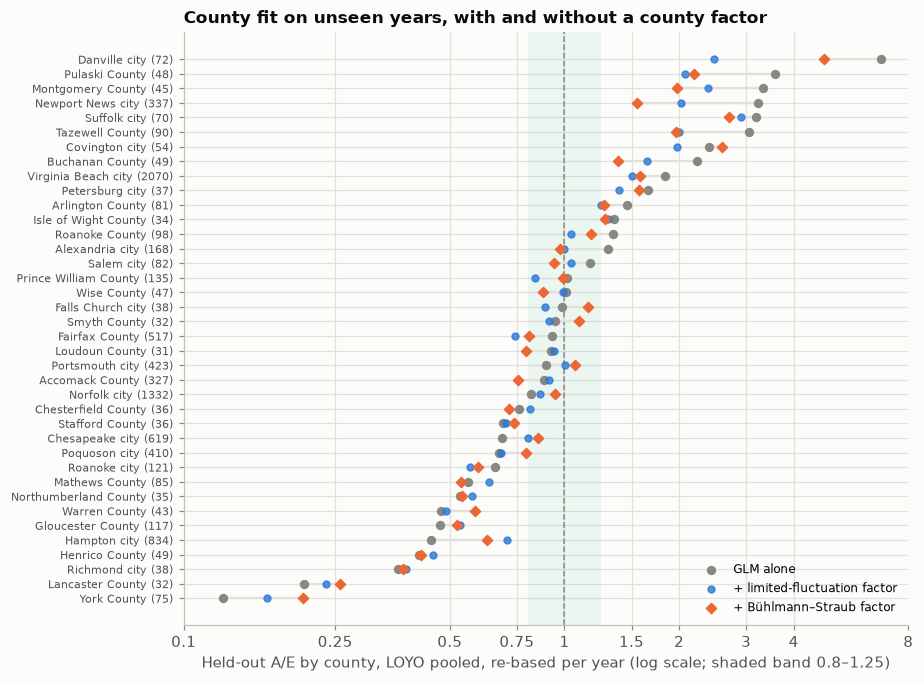

In [12]:
t_fs, _ = pp.county_ae_out_of_fold(oof, FS, names=names)
t_bs, _ = pp.county_ae_out_of_fold(oof, FS_BS, names=names)
t_lf, _ = pp.county_ae_out_of_fold(oof, FS_LF, names=names)
big = t_fs[t_fs["claims"] >= 30].sort_values("ae").index
fig, ax = plt.subplots(figsize=(8.5, 7))
yy = np.arange(len(big))
ax.scatter(t_fs.loc[big, "ae"], yy, color=MUTED, s=26, label="GLM alone", zorder=3)
ax.scatter(t_lf.loc[big, "ae"], yy, color=BLUE, s=20, marker="o", label="+ limited-fluctuation factor", zorder=3, alpha=0.8)
ax.scatter(t_bs.loc[big, "ae"], yy, color=ORANGE, s=22, marker="D", label="+ Bühlmann–Straub factor", zorder=4)
for i, c in enumerate(big):
    ax.plot([t_fs.loc[c, "ae"], t_bs.loc[c, "ae"]], [i, i], color=GRID, lw=1.5, zorder=2)
ax.axvspan(0.8, 1.25, color=AQUA, alpha=0.07, lw=0)
ax.set_yticks(yy, [f"{names.get(c, c)} ({int(t_fs.loc[c, 'claims'])})" for c in big], fontsize=7.5)
log_rel_axis(ax, 0.1, 8)
ax.set(xlabel="Held-out A/E by county, LOYO pooled, re-based per year (log scale; shaded band 0.8–1.25)",
       title="County fit on unseen years, with and without a county factor")
ax.legend(loc="lower right", fontsize=8)
save(fig, "county_ae_validation")

### 2d. Decision and the final county factors
**Rule (stated before looking at the table):** use the method that improves held-out county A/E **without** making the overall held-out fit worse.

Chosen: buhlmann_straub. Re-centring scale 1.0520 (so the statewide total is unchanged).


                         name  f_act  freq_ae  Z_freq     s_n  sev_ae  Z_sev  factor  lf_factor
county                                                                                         
51810     Virginia Beach city   2070    1.290     0.0  2072.0   1.147  0.984   1.204      1.415
51710            Norfolk city   1332    1.138     0.0  1333.0   0.795  0.976   0.842      0.947
51650            Hampton city    834    0.637     0.0   834.0   0.760  0.961   0.809      0.574
51550         Chesapeake city    619    0.964     0.0   622.0   0.778  0.949   0.831      0.845
51059          Fairfax County    517    1.309     0.0   518.0   0.964  0.939   1.017      1.161
51740         Portsmouth city    423    1.013     0.0   425.0   0.819  0.927   0.876      0.910
51735           Poquoson city    410    1.053     0.0   409.0   0.782  0.925   0.840      0.919
51700       Newport News city    337    1.510     0.0   339.0   1.757  0.910   1.777      1.583
51001         Accomack County    327    

saved reports\figures\07_county_factors.png


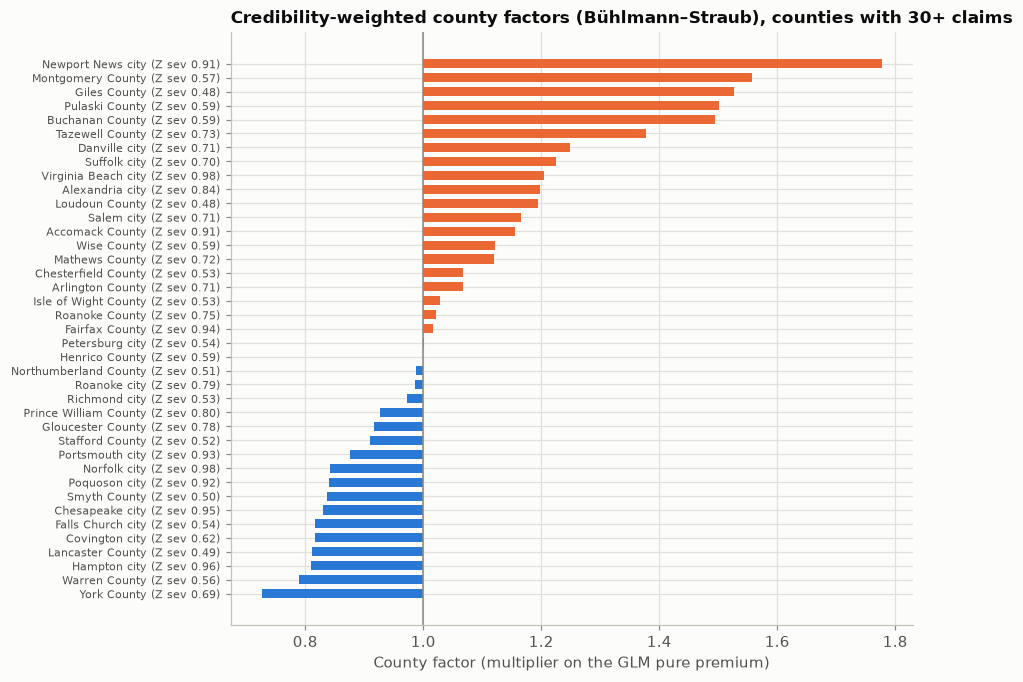

In [13]:
CHOSEN = "buhlmann_straub"
final, cf_tbl, cf_par = pp.with_county_factors(model, cells, claims, CHOSEN)
_, lf_final, lf_par2 = pp.with_county_factors(model, cells, claims, "limited_fluctuation", sev_cv=SEV_CV)
cf_tbl["name"] = cf_tbl.index.map(names)
cf_tbl["lf_factor"] = lf_final["factor"]
print(f"Chosen: {CHOSEN}. Re-centring scale {cf_par['recentre_scale']:.4f} (so the statewide total is unchanged).")
assert np.isclose(final.predict(cells).sum(), model.predict(cells, county=False).sum())
show = cf_tbl.sort_values("s_n", ascending=False)
print(show.head(25)[["name", "f_act", "freq_ae", "Z_freq", "s_n", "sev_ae", "Z_sev", "factor", "lf_factor"]].round(3).to_string())
print(f"\nCounties with any claims: {(cf_tbl['s_n'] > 0).sum()}; factor range {cf_tbl['factor'].min():.2f}-{cf_tbl['factor'].max():.2f}; "
      f"counties with no claims get {cf_tbl.loc[cf_tbl['s_n'] == 0, 'factor'].median():.3f} (the re-centring scale)")

top = show[show["s_n"] >= 30].sort_values("factor")
fig, ax = plt.subplots(figsize=(8, 7))
yy = np.arange(len(top))
ax.barh(yy, top["factor"] - 1, left=1, color=[ORANGE if v > 1 else BLUE for v in top["factor"]], height=0.65)
ax.set_yticks(yy, [f"{n} (Z sev {z:.2f})" for n, z in zip(top["name"], top["Z_sev"])], fontsize=7.5)
ax.axvline(1, color=MUTED, lw=1)
ax.set(xlabel="County factor (multiplier on the GLM pure premium)",
       title="Credibility-weighted county factors (Bühlmann–Straub), counties with 30+ claims")
save(fig, "county_factors")

## 3. A Tweedie GLM for pure premium directly
**Tweedie distribution:** a family of distributions with variance = φ × mean^p, where **p** is the *power*.
- p = 1 is Poisson-like (counts) and p = 2 is Gamma (sizes).
- **Between 1 and 2** it's a *compound Poisson–Gamma*: a Poisson number of claims, each with a Gamma size. That gives exactly what loss cost per cell looks like: a lump of exact zeros (no claims) plus a continuous, skewed spread of positive amounts.

So one GLM can model losses ÷ exposure directly.

**Choosing p.**
- *Theory:* the power and the Gamma shape α of individual claims are linked by p = (α + 2) ÷ (α + 1). Milestone 8's Gamma shape was α ≈ 0.96, giving p ≈ 1.51.
- *Data:* a grid from 1.2 to 1.8, each scored on development-year LOYO with the same yardstick (deviance at power 1.5, and Gini). The best one is chosen.

**Features:** the union of the frequency and severity features (all seven), so the comparison is about *structure* (one model vs two), not feature choice.

theory: p = (alpha + 2) / (alpha + 1) with alpha = 0.958 -> 1.511
grid (development LOYO), chosen p = 1.7
saved reports\figures\07_tweedie_power.png


                                            freq x sev  Tweedie p=1.7  Tweedie / freq x sev
occupancy_group[multi-unit residential]          2.098          2.948                 1.405
occupancy_group[non-residential]                 3.067          5.565                 1.815
construction_band[before 1960]                   2.788          2.277                 0.817
construction_band[1960-1979]                     3.523          2.978                 0.845
construction_band[2000 or later]                 0.576          0.593                 1.029
building_coverage_band[$0 (contents only)]       0.280          0.416                 1.489
building_coverage_band[under $100K]              0.692          1.537                 2.223
building_coverage_band[$100K-$249K]              0.853          1.193                 1.399
flood_zone_group[B/C/X moderate-low risk]        0.341          0.486                 1.424
floors_group[1]                                  1.001          1.037           

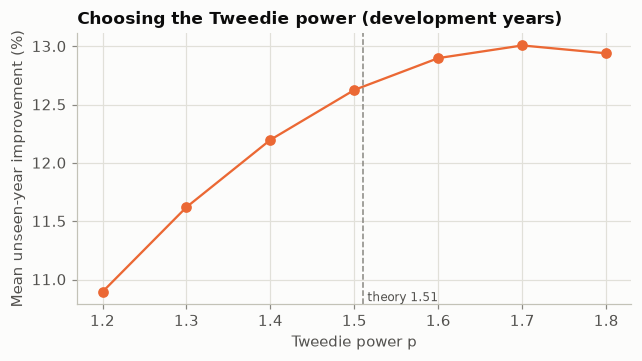

In [14]:
print(f"theory: p = (alpha + 2) / (alpha + 1) with alpha = 0.958 -> {pp.tweedie_power_from_gamma_shape(0.958):.3f}")
print(f"grid (development LOYO), chosen p = {TW_POWER}")
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(grid_summ.index, grid_summ["improvement_rebased_pct"], marker="o", color=ORANGE)
ax.axvline(pp.tweedie_power_from_gamma_shape(0.958), color=MUTED, ls="--", lw=1)
ax.text(pp.tweedie_power_from_gamma_shape(0.958), ax.get_ylim()[0], " theory 1.51", fontsize=8, color=INK_2, va="bottom")
ax.set(xlabel="Tweedie power p", ylabel="Mean unseen-year improvement (%)", title="Choosing the Tweedie power (development years)")
save(fig, "tweedie_power")

tw = pp.fit_tweedie(cells, TW_FEATURES, TW_POWER, bases=SB)
tw_rel = tw.relativities()
fs_rel = rel.assign(col=rel["feature"] + "[" + rel["level"] + "]").set_index("col")["pure_premium_rel"]
rel_cmp = pd.DataFrame({"freq x sev": fs_rel.reindex(tw_rel.index), f"Tweedie p={TW_POWER:g}": tw_rel})
rel_cmp["Tweedie / freq x sev"] = rel_cmp.iloc[:, 1] / rel_cmp.iloc[:, 0]
print(rel_cmp.round(3).to_string())
print(f"Tweedie dispersion phi = {tw.phi:.1f}; off-balance {tw.off_balance:.4f}")

**Do the models balance dollars by segment?** A pricing model should, on the data it was fitted to, predict roughly the right total dollars for each level of each factor (A/E ≈ 1). Here's the check in-sample, with predictions re-based within each year so storm-year levels cancel out.

*Why the Tweedie can fail this:* a log-link GLM's fitting equations weight each cell by mean^(1−p). At p = 1.7 that's mean^(−0.7), so high-cost cells (commercial and multi-unit buildings) get **less** weight, and the model is free to miss their dollar total. Poisson (p = 1) weights everyone equally and balances counts exactly.

In [15]:
mc = cells[cells["exposure"] > 0].copy()
for name, pr in [("freq x sev", model.predict(mc, county=False)), (f"Tweedie p={TW_POWER:g}", tw.predict(mc))]:
    mc[name] = pr * mc.groupby("year")[pp.LOSS].transform("sum") / pd.Series(pr, index=mc.index).groupby(mc["year"]).transform("sum")
bal = []
for f in ["occupancy_group", "building_coverage_band", "flood_zone_group", "construction_band", "elevated"]:
    g = mc.groupby(f, observed=True)[[pp.LOSS, "freq x sev", f"Tweedie p={TW_POWER:g}"]].sum()
    for lvl, r in g.iterrows():
        bal.append({"feature": LABELS[f], "level": str(lvl), "in-sample A/E freq x sev": r[pp.LOSS] / r["freq x sev"],
                    f"in-sample A/E Tweedie p={TW_POWER:g}": r[pp.LOSS] / r[f"Tweedie p={TW_POWER:g}"]})
balance = pd.DataFrame(bal)
print(balance.round(3).to_string(index=False))

          feature                   level  in-sample A/E freq x sev  in-sample A/E Tweedie p=1.7
        Occupancy  multi-unit residential                     1.334                        1.221
        Occupancy         non-residential                     0.745                        0.497
        Occupancy single-unit residential                     1.005                        1.166
Building coverage      $0 (contents only)                     1.610                        1.007
Building coverage             $100K-$249K                     1.076                        1.074
Building coverage           $250K or more                     0.987                        1.194
Building coverage             under $100K                     0.792                        0.437
       Flood zone           A/V high risk                     0.979                        1.030
       Flood zone B/C/X moderate-low risk                     1.077                        0.915
       Year built             

Held-out comparison (LOYO 16 years and the 2021-2025 holdout):
                                           LOYO 16 years                             development LOYO 2010-2020                             holdout 2021-2025        held-out county A/E                      
                                      mean improvement % non-cat %   cat % mean Gini         mean improvement % non-cat %   cat % mean Gini     improvement %   Gini      mean |log A/E| share within 0.8-1.25
model                                                                                                                                                                                                         
freq x sev                                        10.226     9.044  15.348     0.456                     12.702    11.737  15.276     0.493             6.415  0.428               0.497                 0.263
freq x sev + county (buhlmann_straub)             10.725    11.289   8.280     0.473                     12.2

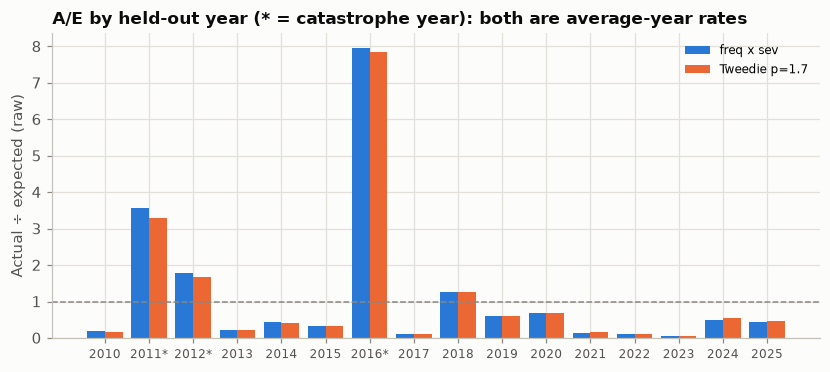

In [16]:
print("Held-out comparison (LOYO 16 years and the 2021-2025 holdout):")
print(val_tbl.loc[[FS, FS_BS, TW]].round(3).to_string())
# A/E by year (raw) for the two structures, and by feature (re-based, out of fold)
ae_year = sc_all.pivot(index="test_year", columns="model", values="actual_over_expected")[[FS, TW]]
print(ae_year.round(2).T.to_string())
o = oof.copy()
for name in [FS, TW]:
    o[f"rb_{name}"] = o[name] * o.groupby("year")[pp.LOSS].transform("sum") / o.groupby("year")[name].transform("sum")
rows = []
for f in ["flood_zone_group", "construction_band", "occupancy_group", "building_coverage_band", "elevated"]:
    g = o.groupby(f, observed=True)[[pp.LOSS, f"rb_{FS}", f"rb_{TW}"]].sum()
    for lvl, r in g.iterrows():
        rows.append({"feature": LABELS[f], "level": str(lvl), "A/E freq x sev": r[pp.LOSS] / r[f"rb_{FS}"],
                     "A/E Tweedie": r[pp.LOSS] / r[f"rb_{TW}"]})
ae_feat = pd.DataFrame(rows)
print(ae_feat.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(ae_year))
ax.bar(x - 0.2, ae_year[FS], width=0.4, color=BLUE, label="freq x sev")
ax.bar(x + 0.2, ae_year[TW], width=0.4, color=ORANGE, label=f"Tweedie p={TW_POWER:g}")
ax.axhline(1, color=MUTED, ls="--", lw=1)
ax.set_xticks(x, [f"{y}{'*' if y in val.CAT_YEARS else ''}" for y in ae_year.index], fontsize=8)
ax.set(ylabel="Actual ÷ expected (raw)", title="A/E by held-out year (* = catastrophe year): both are average-year rates")
ax.legend(fontsize=8)
save(fig, "ae_by_year")

**Lift charts and the double lift.**
- A **lift chart** sorts cells by predicted loss cost, cuts them into 10 groups of equal exposure, and compares actual with predicted. The steeper the actual bars climb, the better the ranking.
- A **double-lift chart** compares *two* models directly. It sorts cells by the **ratio** model A ÷ model B, so the first decile is where A is much lower than B and the last is where A is much higher. In each decile it shows actual and both models' predictions. Whichever model's line tracks the actual bars is right where the two disagree.
- The **Gini coefficient** summarizes a ranking. Sort from lowest to highest predicted loss cost, and plot cumulative share of exposure against cumulative share of actual losses. Gini = 1 − 2 × (area under that curve): 0 = random ranking, 1 = all losses in the very last sliver of exposure.

freq x sev top/bottom decile actual: 25.1  pooled Gini 0.481
Tweedie p=1.7 top/bottom decile actual: 27.3  pooled Gini 0.493


saved reports\figures\07_lift_and_double_lift.png
        losses_relative  a_relative  b_relative  ratio_a_over_b
decile                                                         
1                 0.720       0.957       2.092           0.458
2                 1.279       1.010       1.385           0.729
3                 0.548       0.603       0.712           0.846
4                 0.532       0.523       0.562           0.930
5                 0.673       0.673       0.676           0.995
6                 1.215       1.015       0.932           1.088
7                 0.823       0.900       0.770           1.169
8                 1.178       1.134       0.895           1.267
9                 0.977       1.124       0.789           1.425
10                2.055       2.061       1.187           1.736
mean |model - actual| across double-lift deciles: {'freq x sev': 0.104, 'Tweedie': 0.335}
end deciles (1, 2, 9, 10): {'freq x sev': 0.165, 'Tweedie': 0.633}


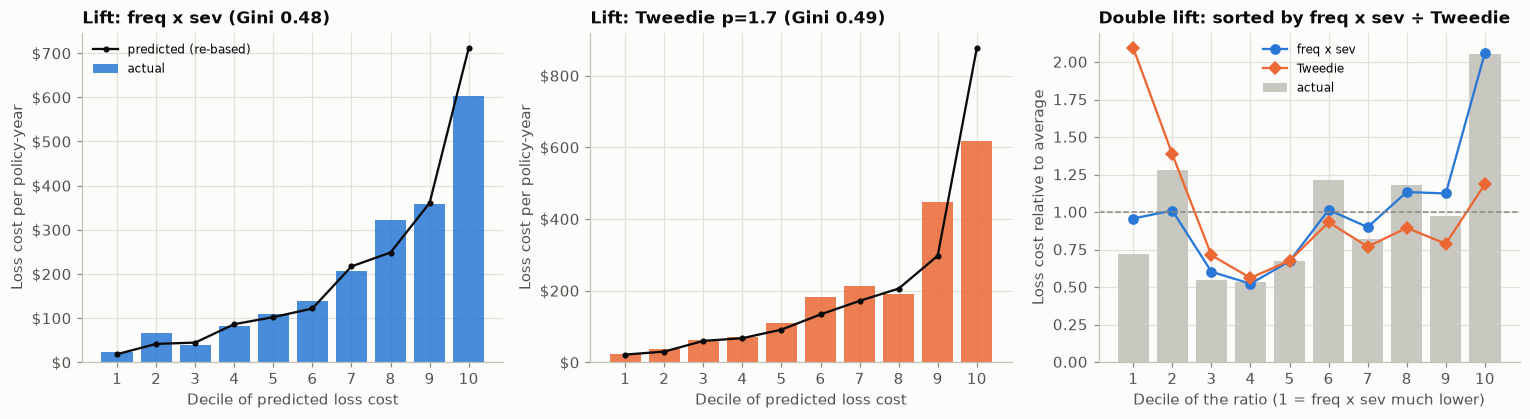

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, name, rank, col in [(axs[0], FS, oof["rank_freq_x_sev"], BLUE), (axs[1], TW, oof["rank_tweedie"], ORANGE)]:
    rb = oof[name] * oof.groupby("year")[pp.LOSS].transform("sum") / oof.groupby("year")[name].transform("sum")
    lt = pp.lift_table(oof[pp.LOSS], rb, oof["exposure"], rank_by=rank)
    ax.bar(lt.index, lt["actual_loss_cost"], color=col, alpha=0.85, label="actual")
    ax.plot(lt.index, lt["pred_loss_cost"], color=INK, marker="o", ms=3, label="predicted (re-based)")
    g = pp.loss_gini(oof[pp.LOSS], rank * oof["exposure"], oof["exposure"])
    ax.set(title=f"Lift: {name} (Gini {g:.2f})", xlabel="Decile of predicted loss cost", ylabel="Loss cost per policy-year")
    ax.set_xticks(lt.index)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"${v:,.0f}"))
    print(name, "top/bottom decile actual:", round(lt["actual_loss_cost"].iloc[-1] / lt["actual_loss_cost"].iloc[0], 1), " pooled Gini", round(g, 3))
axs[0].legend(fontsize=8)
rb_fs = oof[FS] * oof.groupby("year")[pp.LOSS].transform("sum") / oof.groupby("year")[FS].transform("sum")
rb_tw = oof[TW] * oof.groupby("year")[pp.LOSS].transform("sum") / oof.groupby("year")[TW].transform("sum")
dl = pp.double_lift(oof[pp.LOSS], rb_fs, rb_tw, oof["exposure"])
ax = axs[2]
ax.bar(dl.index, dl["losses_relative"], color="#c9c8c0", label="actual")
ax.plot(dl.index, dl["a_relative"], color=BLUE, marker="o", label="freq x sev")
ax.plot(dl.index, dl["b_relative"], color=ORANGE, marker="D", label="Tweedie")
ax.axhline(1, color=MUTED, ls="--", lw=1)
ax.set(title="Double lift: sorted by freq x sev ÷ Tweedie", xlabel="Decile of the ratio (1 = freq x sev much lower)",
       ylabel="Loss cost relative to average")
ax.set_xticks(dl.index)
ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "lift_and_double_lift")
print(dl[["losses_relative", "a_relative", "b_relative", "ratio_a_over_b"]].round(3).to_string())
err = pd.Series({"freq x sev": (dl["a_relative"] - dl["losses_relative"]).abs().mean(),
                 "Tweedie": (dl["b_relative"] - dl["losses_relative"]).abs().mean()})
print("mean |model - actual| across double-lift deciles:", err.round(3).to_dict())
print("end deciles (1, 2, 9, 10):", {k: round(float(v), 3) for k, v in {
    "freq x sev": (dl["a_relative"] - dl["losses_relative"]).abs().iloc[[0, 1, 8, 9]].mean(),
    "Tweedie": (dl["b_relative"] - dl["losses_relative"]).abs().iloc[[0, 1, 8, 9]].mean()}.items()})

**Recommendation for the app: frequency × severity, with the Bühlmann–Straub county factor.** (The numbers are in the tables above and in `reports/06_pure_premium.md`.)
- On the **development years** the two structures are essentially tied. On all 16 LOYO years the Tweedie is somewhat better on average, mostly in quiet years, while frequency × severity is better in catastrophe years.
- The **double lift** favours frequency × severity where the two disagree most (the end deciles).
- With the county factor, frequency × severity is best on the **2021–2025 holdout**.
- It explains **why**: "how often" and "how big" separately. That's what the app promises ("the reasons behind it"), and it shows effects like floors, which cancel out in the loss cost.

The Tweedie stays as a cross-check and as the baseline for the XGBoost Tweedie in the model-comparison milestone.

## 4. Loss ratios: actual NFIP premiums vs losses
A **loss ratio** = losses ÷ premiums. A ratio of 0.60 means 60 cents of every premium dollar went to paying claims.
- **Earned premium:** each policy's premium is spread evenly over its term, so a year earns the part of the premium for the days covered in that year. That's the same method as earned exposure.
- `totalInsurancePremiumOfThePolicy` is the premium itself. `policyCost` adds fees and surcharges (federal policy fee, HFIAA surcharge, reserve fund assessment), shown as an alternative.
- **Both are in nominal dollars** (the dollars of each year), compared with nominal losses.

**Caveats.**
- NFIP premiums are not a pure premium. They also carry expenses (agent commissions, insurer service fees), a catastrophe and reserve loading, and **national** cross-subsidies: Virginia policyholders help pay for Louisiana and Texas hurricanes.
- **Risk Rating 2.0** (from October 2021) re-priced every policy, with statutory limits on yearly increases (the "glide path"), so recent premiums are still moving toward their target.
- So a low loss ratio does not mean "overcharged" in an absolute sense. The *relative* comparison between segments is the useful part.

In [18]:
prem = pp.load_cell_premium()
cp = cells.merge(prem, on=bd.CELL_KEYS, how="left").fillna({"earned_premium": 0.0, "earned_policy_cost": 0.0})
assert np.isclose(cp["exposure"].sum(), cells["exposure"].sum())
tot = cp[["losses_nominal", "earned_premium", "earned_policy_cost", "exposure"]].sum()
print(f"2010-2025: losses ${tot['losses_nominal']:,.0f}; earned premium ${tot['earned_premium']:,.0f}; "
      f"policy cost incl. fees ${tot['earned_policy_cost']:,.0f}")
print(f"Loss ratio {tot['losses_nominal'] / tot['earned_premium']:.1%} (premium), {tot['losses_nominal'] / tot['earned_policy_cost']:.1%} (incl. fees); "
      f"average premium ${tot['earned_premium'] / tot['exposure']:,.0f} per policy-year")
ly = cp.groupby("year")[["losses_nominal", "earned_premium", "exposure"]].sum()
ly["loss ratio"] = ly["losses_nominal"] / ly["earned_premium"]
ly["premium per policy-year"] = ly["earned_premium"] / ly["exposure"]
print(ly[["loss ratio", "premium per policy-year"]].round(3).T.to_string())
med = ly["loss ratio"].median()
print(f"median year {med:.1%}; years above 50%: {list(ly.index[ly['loss ratio'] > 0.5])}")

lr_rows = []
for f in ["flood_zone_group", "construction_band", "occupancy_group", "building_coverage_band", "elevated", "primary_residence", "coastal_tidal"]:
    g = cp.groupby(f, observed=True)[["losses_nominal", "earned_premium", "exposure"]].sum()
    for lvl, r in g.iterrows():
        lr_rows.append({"feature": LABELS.get(f, "Tidewater (tidal)"), "level": str(lvl), "exposure share": r["exposure"] / tot["exposure"],
                        "premium per policy-year": r["earned_premium"] / r["exposure"],
                        "loss ratio": r["losses_nominal"] / r["earned_premium"]})
lr_tbl = pd.DataFrame(lr_rows)
print(lr_tbl.round(3).to_string(index=False))

2010-2025: losses $220,183,315; earned premium $1,136,908,062; policy cost incl. fees $1,397,488,112
Loss ratio 19.4% (premium), 15.8% (incl. fees); average premium $767 per policy-year
year                        2010     2011     2012     2013     2014     2015     2016     2017     2018     2019     2020     2021     2022     2023     2024     2025
loss ratio                 0.039    0.606    0.338    0.046    0.086    0.066    1.072    0.022    0.237    0.115    0.128    0.029    0.027    0.016    0.135    0.116
premium per policy-year  676.311  702.020  716.768  756.754  790.701  794.823  782.534  790.736  781.943  785.413  810.437  845.723  799.046  698.787  749.906  800.475
median year 10.1%; years above 50%: [2011, 2016]
          feature                   level  exposure share  premium per policy-year  loss ratio
       Flood zone           A/V high risk           0.510                 1065.146       0.208
       Flood zone B/C/X moderate-low risk           0.490              

**Modelled loss cost vs premium by segment.** For 2023–2025 (mostly Risk Rating 2.0 premiums), the comparison is the model's expected loss (2025 dollars, average year, with county factors) against earned premium for each segment:

> relative indication = (segment's modelled loss ÷ segment's premium) ÷ (statewide modelled loss ÷ statewide premium)

Dividing by the statewide ratio removes the overall expense and catastrophe loading. **Above 1:** the segment's premium is low *relative to its modelled risk* (it looks under-priced compared with the average segment). **Below 1:** it looks over-priced. These are relative signals, not verdicts.

2023-2025: modelled loss $48,633,827 vs earned premium $181,121,976 -> modelled loss ratio 26.9%
          feature                   level  modelled loss per policy-year  premium per policy-year  relative indication
       Flood zone           A/V high risk                        295.607                  935.910                1.176
       Flood zone B/C/X moderate-low risk                         90.079                  529.407                0.634
       Year built               1960-1979                        367.355                  807.709                1.694
       Year built               1980-1999                         95.363                  717.554                0.495
       Year built           2000 or later                         52.415                  656.889                0.297
       Year built             before 1960                        284.929                  811.381                1.308
        Occupancy  multi-unit residential                        437.8

saved reports\figures\07_loss_ratios.png


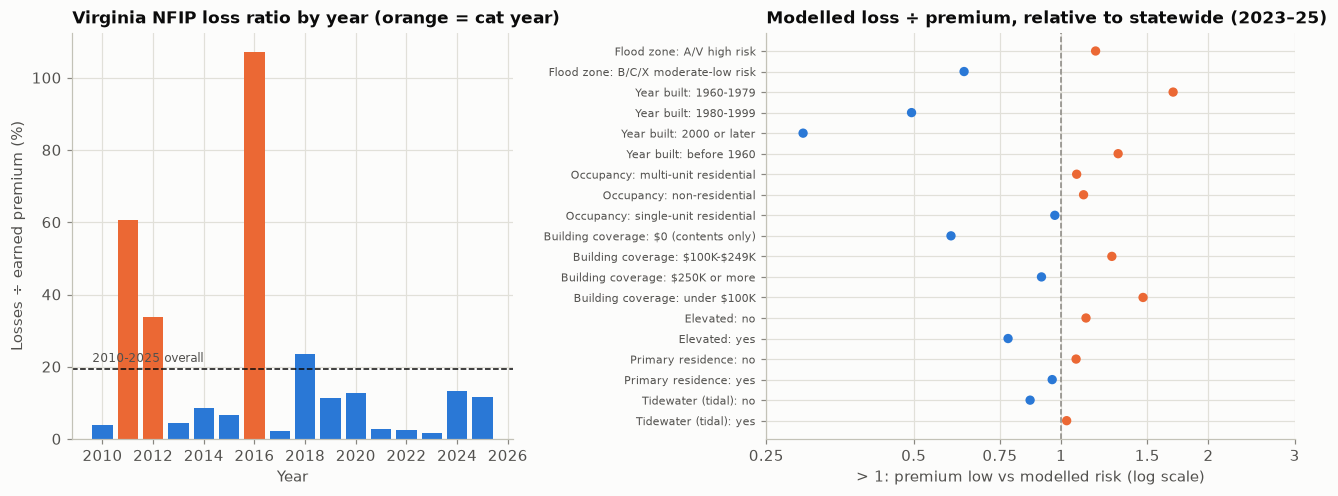

In [19]:
rec = cp[cp["year"] >= 2023].copy()
rec["modelled"] = final.predict(rec)
st = rec["modelled"].sum() / rec["earned_premium"].sum()
print(f"2023-2025: modelled loss ${rec['modelled'].sum():,.0f} vs earned premium ${rec['earned_premium'].sum():,.0f} -> modelled loss ratio {st:.1%}")
ind_rows = []
for f in ["flood_zone_group", "construction_band", "occupancy_group", "building_coverage_band", "elevated", "primary_residence", "coastal_tidal"]:
    g = rec.groupby(f, observed=True)[["modelled", "earned_premium", "exposure"]].sum()
    for lvl, r in g.iterrows():
        ind_rows.append({"feature": LABELS.get(f, "Tidewater (tidal)"), "level": str(lvl),
                         "modelled loss per policy-year": r["modelled"] / r["exposure"],
                         "premium per policy-year": r["earned_premium"] / r["exposure"],
                         "relative indication": (r["modelled"] / r["earned_premium"]) / st})
ind = pd.DataFrame(ind_rows)
print(ind.round(3).to_string(index=False))
cty = rec.groupby("county")[["modelled", "earned_premium", "exposure", "claims"]].sum()
cty = cty[cty["exposure"] >= 3000]
cty["relative indication"] = (cty["modelled"] / cty["earned_premium"]) / st
cty["name"] = cty.index.map(names)
print("\nCounties (3,000+ policy-years in 2023-2025):")
print(cty.sort_values("relative indication")[["name", "exposure", "relative indication"]].round(2).to_string())

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axs[0]
ax.bar(ly.index, 100 * ly["loss ratio"], color=[ORANGE if y in val.CAT_YEARS else BLUE for y in ly.index])
ax.axhline(100 * tot["losses_nominal"] / tot["earned_premium"], color=INK, lw=1, ls="--")
ax.text(ly.index[0] - 0.4, 100 * tot["losses_nominal"] / tot["earned_premium"] + 2, "2010-2025 overall", fontsize=8, color=INK_2)
ax.set(title="Virginia NFIP loss ratio by year (orange = cat year)", ylabel="Losses ÷ earned premium (%)", xlabel="Year")
ax = axs[1]
s = ind.copy()
s["lab"] = s["feature"] + ": " + s["level"].replace({"True": "yes", "False": "no"})
yy = np.arange(len(s))[::-1]
ax.scatter(s["relative indication"], yy, color=[ORANGE if v > 1 else BLUE for v in s["relative indication"]], s=26, zorder=3)
ax.set_yticks(yy, s["lab"], fontsize=7.5)
log_rel_axis(ax, 0.25, 3)
ax.set(title="Modelled loss ÷ premium, relative to statewide (2023–25)", xlabel="> 1: premium low vs modelled risk (log scale)")
fig.tight_layout()
save(fig, "loss_ratios")

## 5. Rating worksheets: five example Virginia profiles
Each worksheet multiplies the factors step by step for a *typical insured building with these characteristics in that county*. It is an area-level average, **not** a quote or a prediction for any particular property.


=== Virginia Beach, 1960s ranch house in the floodplain ===
Base frequency (claims per 1,000 policy-years)                                                   4.82
  x Flood zone: A/V high risk                                                    1.000           4.82
  x Year built: 1960-1979                                                        2.748          13.26
  x Floors: 1                                                                    0.892          11.82
Base severity (dollars per claim)                                                           28,497.89
  x Occupancy: single-unit residential                                           1.000      28,497.89
  x Year built: 1960-1979                                                        1.282      36,535.45
  x Building coverage: $250K or more                                             1.000      36,535.45
  x Flood zone: A/V high risk                                                    1.000      36,535.45
  x Floors: 1        

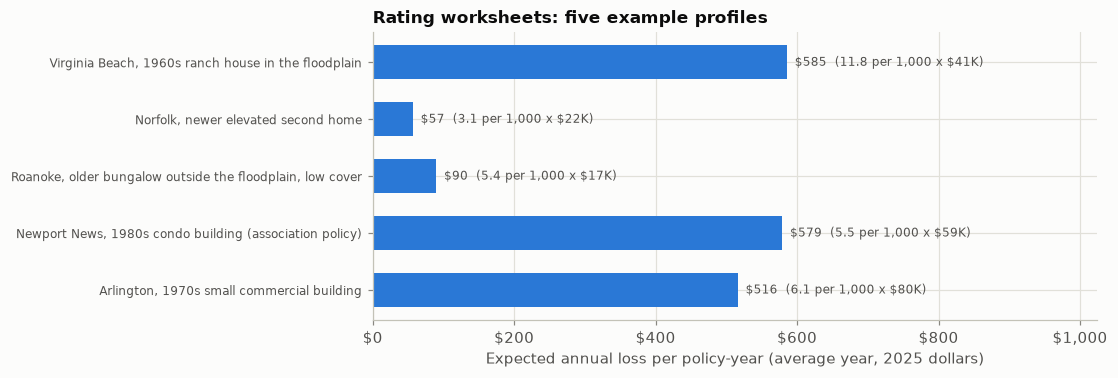

In [20]:
PROFILES = [
    ("Virginia Beach, 1960s ranch house in the floodplain", "51810",
     dict(flood_zone_group="A/V high risk", occupancy_group="single-unit residential", construction_band="1960-1979",
          floors_group="1", elevated=False, primary_residence=True, building_coverage_band="$250K or more")),
    ("Norfolk, newer elevated second home", "51710",
     dict(flood_zone_group="A/V high risk", occupancy_group="single-unit residential", construction_band="2000 or later",
          floors_group="2", elevated=True, primary_residence=False, building_coverage_band="$250K or more")),
    ("Roanoke, older bungalow outside the floodplain, low cover", "51770",
     dict(flood_zone_group="B/C/X moderate-low risk", occupancy_group="single-unit residential", construction_band="before 1960",
          floors_group="1", elevated=False, primary_residence=True, building_coverage_band="under $100K")),
    ("Newport News, 1980s condo building (association policy)", "51700",
     dict(flood_zone_group="A/V high risk", occupancy_group="multi-unit residential", construction_band="1980-1999",
          floors_group="3+", elevated=False, primary_residence=False, building_coverage_band="$250K or more")),
    ("Arlington, 1970s small commercial building", "51013",
     dict(flood_zone_group="B/C/X moderate-low risk", occupancy_group="non-residential", construction_band="1960-1979",
          floors_group="2", elevated=False, primary_residence=False, building_coverage_band="$100K-$249K")),
]

def lvl_rel(model_, f, lvl):
    col = f"{f}[{lvl}]"
    return float(np.exp(model_.params[col])) if col in model_.params.index else 1.0

ws_rows = []
for title, county, feat in PROFILES:
    row = pd.DataFrame([{**feat, "county": county, "year": 2025, "exposure": 1.0, "post_firm": False}])
    lines = [("Base frequency (claims per 1,000 policy-years)", None, 1000 * base_f)]
    f_ = base_f
    for f in FF:
        r = lvl_rel(freq, f, str(feat[f])); f_ *= r
        lines.append((f"  x {LABELS[f]}: {feat[f]}", r, 1000 * f_))
    lines.append(("Base severity (dollars per claim)", None, base_s))
    s_ = base_s
    for f in SF:
        r = lvl_rel(sev, f, str(feat[f])); s_ *= r
        lines.append((f"  x {LABELS[f]}: {feat[f]}", r, s_))
    pp_ = f_ * s_
    lines.append(("Frequency x severity (dollars per policy-year)", None, pp_))
    for lab, r in [("x large-loss load (no cap)", final.large_loss_load), ("x ICC bridge", final.icc_bridge), ("x off-balance", final.off_balance)]:
        pp_ *= r; lines.append((lab, r, pp_))
    c = cf_tbl.loc[county]
    pp_ *= c["factor"]
    lines.append((f"x county factor, {names[county]} (Z freq {c['Z_freq']:.2f}, Z sev {c['Z_sev']:.2f})", c["factor"], pp_))
    check = final.rate(row)[0]
    assert np.isclose(check, pp_), (title, check, pp_)
    print(f"\n=== {title} ===")
    for lab, r, v in lines:
        print(f"{lab:<78} {'' if r is None else f'{r:6.3f}':>7}   {v:>12,.2f}")
    print(f"{'EXPECTED ANNUAL LOSS (average year, 2025 dollars)':<78} {'':>7}   ${pp_:>11,.0f}")
    ws_rows.append({"profile": title, "county": county, "county_name": names[county], **feat,
                    "frequency_per_1000": 1000 * f_, "severity": s_, "county_factor": c["factor"],
                    "expected_annual_loss": pp_, "versus_base_building": pp_ / BASE_PP})
ws = pd.DataFrame(ws_rows)
print()
print(ws[["profile", "frequency_per_1000", "severity", "county_factor", "expected_annual_loss", "versus_base_building"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
yy = np.arange(len(ws))[::-1]
ax.barh(yy, ws["expected_annual_loss"], color=BLUE, height=0.6)
for y_, v, fr, sv_ in zip(yy, ws["expected_annual_loss"], ws["frequency_per_1000"], ws["severity"]):
    ax.text(v, y_, f"  ${v:,.0f}  ({fr:.1f} per 1,000 x ${sv_ / 1000:,.0f}K)", va="center", fontsize=8, color=INK_2)
ax.set_yticks(yy, ws["profile"], fontsize=8)
ax.set_xlim(0, ws["expected_annual_loss"].max() * 1.75)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"${v:,.0f}"))
ax.set(xlabel="Expected annual loss per policy-year (average year, 2025 dollars)", title="Rating worksheets: five example profiles")
save(fig, "rating_worksheets")

## 6. Save the combined model for the app
- `models/pure_premium.json` (committed): the large-loss load, ICC bridge, off-balance and base loss cost, plus the county factors with each county's A/E and Z. It points to the two GLM files.
- `reports/06_*.csv`: the tables.

In [21]:
cf_out = cf_tbl[["name", "f_act", "f_exp", "freq_ae", "Z_freq", "freq_factor", "s_n", "s_act", "s_exp", "sev_ae", "Z_sev",
                 "sev_factor", "factor", "lf_factor"]].rename(columns={"f_act": "claims", "f_exp": "expected_claims", "s_n": "severity_claims",
                 "s_act": "severity_actual", "s_exp": "severity_expected"})
cf_out.index.name = "county"
extra = {"description": "Pure premium = frequency GLM x severity GLM x large-loss load x ICC bridge x off-balance x county factor "
                        "(2025 dollars, average year). County factors: Buhlmann-Straub credibility on county A/E, frequency and "
                        "severity separately, re-centred. LESS CERTAIN than the GLM factors.",
         "created": str(date.today()), "fitted_on_years": [2010, 2025],
         "county_method": CHOSEN, "county_parameters": cf_par,
         "limited_fluctuation_parameters": lf_par2,
         "tweedie_challenger": {"power": TW_POWER, "features": TW_FEATURES},
         "combined_relativities": json.loads(rel.drop(columns="label").to_json(orient="records")),
         "data_file_sha256_16": hashlib.sha256(Path(pp.CELLS_PATH).read_bytes()).hexdigest()[:16]}
pp.save_combined(final, ROOT / "models" / "pure_premium.json", cf_out, extra)
back = pp.load_combined(ROOT / "models" / "pure_premium.json")
assert np.allclose(back.predict(cells), final.predict(cells))
rel.to_csv(ROOT / "reports" / "06_combined_relativities.csv", index=False)
cf_out.to_csv(ROOT / "reports" / "06_county_factors.csv")
val_tbl.to_csv(ROOT / "reports" / "06_credibility_validation.csv")
ae_year.to_csv(ROOT / "reports" / "06_ae_by_year.csv")
rel_cmp.to_csv(ROOT / "reports" / "06_tweedie_relativities.csv")
balance.to_csv(ROOT / "reports" / "06_segment_balance.csv", index=False)
dl.to_csv(ROOT / "reports" / "06_double_lift.csv")
grid_summ.to_csv(ROOT / "reports" / "06_tweedie_power_grid.csv")
sc_all.to_csv(ROOT / "reports" / "06_loyo_scores.csv", index=False)
ae_feat.to_csv(ROOT / "reports" / "06_ae_by_feature.csv", index=False)
pd.concat([lr_tbl.assign(table="loss ratio 2010-2025"), ind.assign(table="relative indication 2023-2025")]).to_csv(
    ROOT / "reports" / "06_loss_ratios.csv", index=False)
ws.to_csv(ROOT / "reports" / "06_rating_worksheets.csv", index=False)
print("saved models/pure_premium.json and reports/06_*.csv")

saved models/pure_premium.json and reports/06_*.csv
